# Sentinel

### A live anomaly detector that learns what is rare for each signal, and explains every alarm

**Utkrishta 2026 · Challenge 2 · Adaptive time-series anomaly detection**
Team **if/elif/else**: Aarohi Gattewar, Phalak Mehta, Harshit Singh

| Event-F1 | Best standard method | False alarms | Speed |
|:---:|:---:|:---:|:---:|
| **0.594** | 0.261, so Sentinel is **2.3×** better | **39** in 365,558 values | **61 µs** per value |

This notebook walks through the project in the same order as our presentation: the problem, the data,
what the data taught us, how Sentinel works (with its real code), a live run, the experiments and the
results. Numbers are computed here from the data and our code, or read from the saved outputs of the
final run.

**Contents**
1. [The problem](#1)
2. [The data](#2)
3. [What the data taught us](#3)
4. [How Sentinel works](#4)
5. [Watch it run on one signal](#5)
6. [The two improvements](#6)
7. [Experiments under a 15-run budget](#7)
8. [Evaluation and results](#8)
9. [Limits and next steps](#9)

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ.setdefault(v, "1")                       # keep the laptop responsive

import inspect, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "sentinel").exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import numpy as np
import pandas as pd
from IPython.display import Code, display

from sentinel.data import load_nab
from sentinel.engine import Sentinel, SentinelParams, run_series
from sentinel.metrics import evaluate_series, window_indices
from sentinel.threshold import TailModel
import eda                                              # our EDA module, scripts/eda.py

%matplotlib inline
import matplotlib.pyplot as plt

# the Sentinel deck colours
BLUE, ORANGE, RED, INK, INK2, MUTED = "#2a78d6", "#eb6834", "#d03b3b", "#0b0b0b", "#52514e", "#898781"
GRID, LINE, GREY = "#ecebe6", "#c3c2b7", "#b5b3ab"
WIN = (137 / 255, 135 / 255, 129 / 255, 0.22)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10.5,
    "axes.edgecolor": LINE, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "legend.labelcolor": INK2, "lines.linewidth": 1.0,
})
pd.set_option("display.max_colwidth", None)

SERIES = {s.name: s for s in load_nab()}
FINAL = pd.read_csv(ROOT / "runs" / "run_06" / "alarms.csv")        # alarms of the submitted run
print(f"{len(SERIES)} series · {sum(len(s) for s in SERIES.values()):,} values · "
      f"{sum(len(s.windows) for s in SERIES.values())} labelled anomaly windows")

58 series · 365,558 values · 116 labelled anomaly windows


In [2]:
CAT = {"realTweets": "Twitter mentions", "realAWSCloudwatch": "Cloud servers (AWS)",
       "realKnownCause": "Known failures", "realTraffic": "Road traffic", "realAdExchange": "Online ad prices",
       "artificialWithAnomaly": "Synthetic, with anomalies", "artificialNoAnomaly": "Synthetic, no anomalies"}
EXPERT = {"level": "spike", "seasonal": "routine", "shift": "new level", "volatility": "jitter", "novelty": "new shape"}


def bands(ax, s):
    for a, b in window_indices(s.timestamps, s.windows):
        ax.axvspan(a, b, color=WIN, lw=0, zorder=0)


def alarms(ax, s, table, size=60):
    a = table[table.series == s.name]
    for _, r in a.iterrows():
        ax.scatter(r.idx, s.values[r.idx], marker="v", s=size, zorder=5, linewidths=0.8,
                   color=ORANGE if r.hit else "white", edgecolors=ORANGE if r.hit else INK2)
    return a


def one_in(score):
    n = 10 ** score
    return "1 in " + (f"{n:,.0f}" if n < 1e6 else f"{n / 1e6:,.0f} million" if n < 1e9 else f"{n / 1e9:,.0f} billion")

<a id="1"></a>
## 1 · The problem

Servers, machines and apps send a number every few minutes. A failure usually shows up in those
numbers first. There are two ways to get it wrong:

* **Stay quiet:** the warning is missed and becomes an outage.
* **Cry wolf:** too many alarms, so people stop listening and miss the real one.

So a good detector must **decide live** (each value arrives once, never peek ahead), **fit any
signal** (CPU, ad prices, traffic, tweets) and raise **few alarms, each with a reason**. The
challenge scores it with **event-F1** over labelled anomaly windows, plus precision, recall,
detection delay and runtime.

<a id="2"></a>
## 2 · The data

The **Numenta Anomaly Benchmark (NAB)**: 58 real and synthetic signals. Experts marked the anomalies
as time windows. The CSVs come from Kaggle (`boltzmannbrain/nab`); the labels come from Numenta's
GitHub, since the Kaggle copy has none.

In [3]:
rows = [{"category": CAT[s.category], "signals": 1, "values": len(s), "anomaly windows": len(s.windows)}
        for s in SERIES.values()]
table = pd.DataFrame(rows).groupby("category").sum().sort_values("values", ascending=False)
table.loc["Total"] = table.sum()
table

,signals,values,anomaly windows
category,,,
Twitter mentions,10,158631,33
Known failures,7,69561,19
Cloud servers (AWS),17,67740,30
"Synthetic, with anomalies",6,24192,6
"Synthetic, no anomalies",5,20160,0
Road traffic,7,15664,14
Online ad prices,6,9610,14
Total,58,365558,116


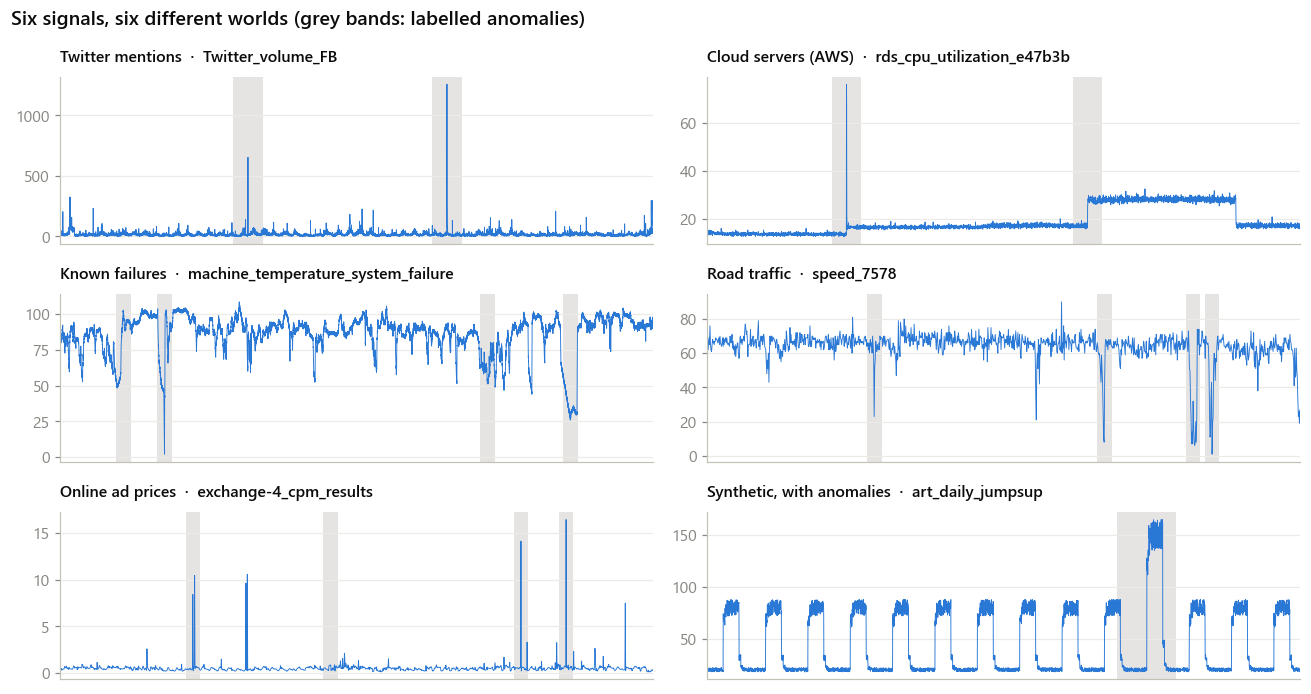

In [4]:
EXAMPLES = ["realTweets/Twitter_volume_FB.csv", "realAWSCloudwatch/rds_cpu_utilization_e47b3b.csv",
            "realKnownCause/machine_temperature_system_failure.csv", "realTraffic/speed_7578.csv",
            "realAdExchange/exchange-4_cpm_results.csv", "artificialWithAnomaly/art_daily_jumpsup.csv"]
fig, axes = plt.subplots(3, 2, figsize=(12, 6.4))
for ax, name in zip(axes.flat, EXAMPLES):
    s = SERIES[name]
    bands(ax, s)
    ax.plot(s.values, color=BLUE, lw=0.6)
    ax.set_title(f"{CAT[s.category]}  ·  {name.split('/')[1][:-4]}", fontsize=10.5)
    ax.set_xlim(0, len(s)); ax.set_xticks([])
fig.suptitle("Six signals, six different worlds (grey bands: labelled anomalies)", x=0.01, ha="left",
             fontsize=13, fontweight="semibold", color=INK)
fig.tight_layout()

> **Takeaway:** the signals share nothing: not their scale, not their rhythm, not their noise.
> One fixed threshold cannot work for all of them.

<a id="3"></a>
## 3 · What the data taught us

### 3.1 · Data quality, and why we barely preprocess

In [5]:
prof = pd.DataFrame([eda.profile(s) for s in SERIES.values()])
pd.Series({
    "missing values (NaN)": int(prof.nan.sum()),
    "duplicate or backward timestamps": int(prof.unsorted_or_dup.sum()),
    "signals with uneven sampling": int((prof.irregular_pct > 0).sum()),
    "sampling steps (minutes)": ", ".join(f"{v:g}" for v in sorted(prof.step_min.unique())),
    "anomaly windows inside the first 300 values": int(prof.windows_in_warmup.sum()),
}, name="").to_frame()

,
missing values (NaN),0
duplicate or backward timestamps,38
signals with uneven sampling,24
sampling steps (minutes),"5, 10, 30, 60"
anomaly windows inside the first 300 values,3


No missing values, a few duplicate timestamps and some uneven gaps (mostly road traffic). We
**read each signal in time order and do nothing else**: no filling, no resampling, no rescaling.
Sentinel learns each signal's own scale as it goes, and a live detector could not use
whole-series statistics anyway.

### 3.2 · Extremes are normal, and many signals have a daily rhythm

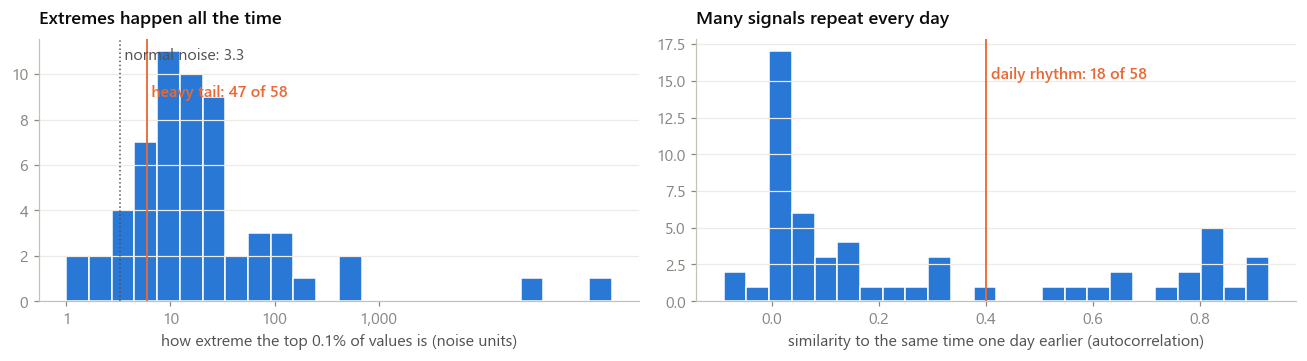

In [6]:
heavy, daily = int((prof.tail_p999 > 6).sum()), int((prof.acf_day >= 0.4).sum())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4))
a1.hist(np.log10(prof.tail_p999.clip(lower=1)), bins=24, color=BLUE, edgecolor="white")
a1.axvline(np.log10(3.3), color=INK2, ls=":", lw=1); a1.text(np.log10(3.3), a1.get_ylim()[1] * 0.92, " normal noise: 3.3", color=INK2)
a1.axvline(np.log10(6), color=ORANGE, lw=1.2); a1.text(np.log10(6), a1.get_ylim()[1] * 0.78, f" heavy tail: {heavy} of 58", color=ORANGE, fontweight="semibold")
a1.set_xticks([0, 1, 2, 3], ["1", "10", "100", "1,000"]); a1.set_xlabel("how extreme the top 0.1% of values is (noise units)")
a1.set_title("Extremes happen all the time")
a2.hist(prof.acf_day.dropna(), bins=24, color=BLUE, edgecolor="white")
a2.axvline(0.4, color=ORANGE, lw=1.2); a2.text(0.41, a2.get_ylim()[1] * 0.85, f"daily rhythm: {daily} of 58", color=ORANGE, fontweight="semibold")
a2.set_xlabel("similarity to the same time one day earlier (autocorrelation)")
a2.set_title("Many signals repeat every day")
fig.tight_layout()

> **Takeaway:** in Gaussian noise the top 0.1% sits at about 3.3 noise units; in **47 of 58** signals
> it is beyond 6. "Big" does not mean "wrong", so the alarm must depend on **how rare a value is for
> that signal**. And **18** signals have a daily rhythm, so Sentinel also compares each value with
> the same time a day earlier.

### 3.3 · The textbook rule drowns in false alarms
The classic rule: alarm when a value is more than 3 standard deviations from the recent average
(here the last day, never the future).

3-sigma rule on all 58 signals: 2,403 alarms for 116 labelled anomalies.  Sentinel: 106 alarms.


Text(0.0, 1.0, 'Tweets about Facebook: 3-sigma rule 114 alarms (grey ticks), Sentinel 2 alarms, both real (orange)')

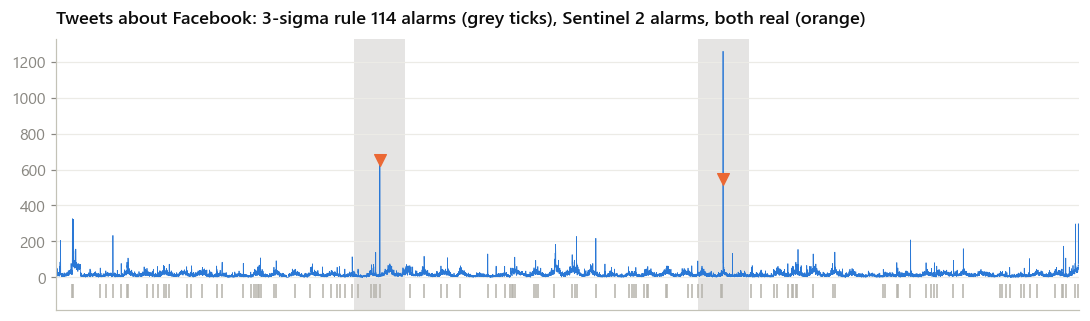

In [7]:
def three_sigma_events(x):
    """Textbook rule: |x - rolling mean| > 3 rolling std over the past day; one event per burst."""
    x = pd.Series(x)
    m = x.rolling(288, min_periods=100).mean().shift(1)
    sd = x.rolling(288, min_periods=100).std().shift(1)
    idx = np.flatnonzero(((x - m).abs() > 3 * sd).to_numpy())
    return idx[np.concatenate([[True], np.diff(idx) > 12])] if len(idx) else idx

total = sum(len(three_sigma_events(s.values)) for s in SERIES.values())
print(f"3-sigma rule on all 58 signals: {total:,} alarms for 116 labelled anomalies.  Sentinel: {len(FINAL)} alarms.")

s = SERIES["realTweets/Twitter_volume_FB.csv"]
ev = three_sigma_events(s.values)
fig, ax = plt.subplots(figsize=(12, 3.2))
bands(ax, s)
ax.plot(s.values, color=BLUE, lw=0.5)
ax.vlines(ev, -0.09 * s.values.max(), -0.03 * s.values.max(), color=GREY, lw=1)
mine = alarms(ax, s, FINAL)
ax.set_xlim(0, len(s)); ax.set_xticks([])
ax.set_title(f"Tweets about Facebook: 3-sigma rule {len(ev)} alarms (grey ticks), Sentinel {len(mine)} alarms, both real (orange)")

### 3.4 · What kinds of anomalies are there?
We sorted every labelled window offline (`eda.classify`, rules in `scripts/eda.py`).

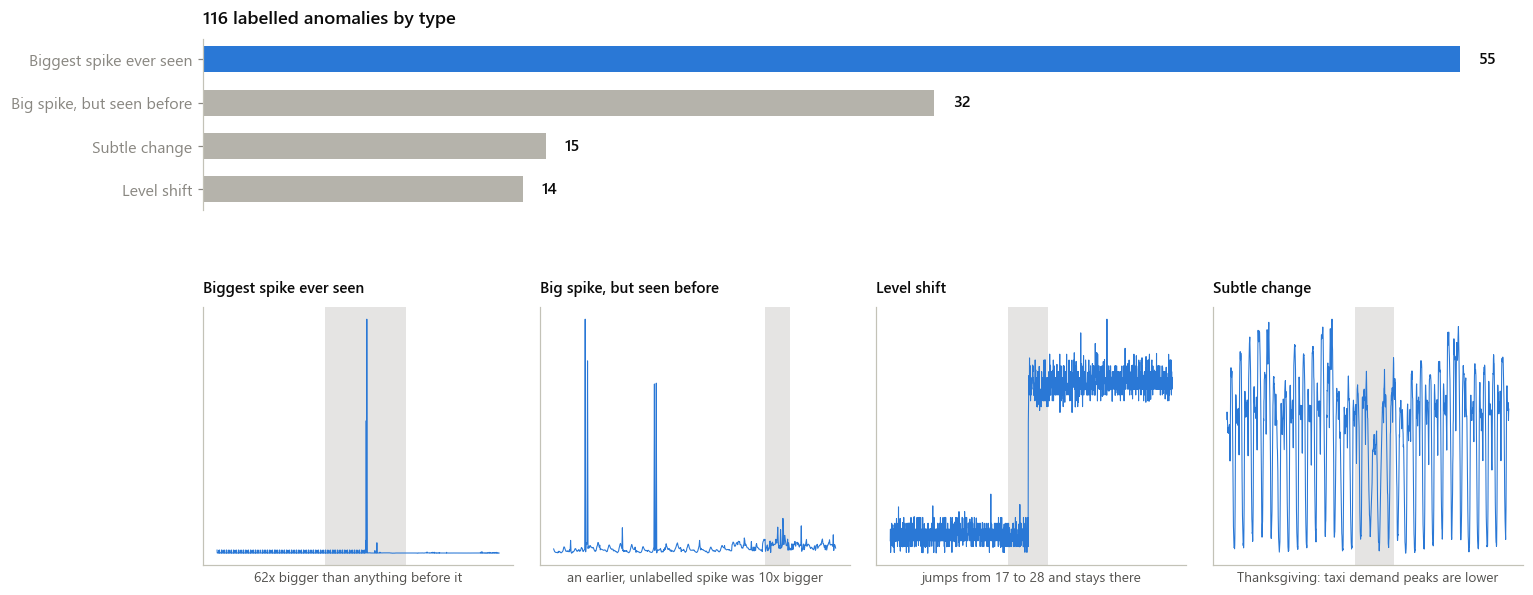

In [8]:
win = pd.DataFrame([r for s in SERIES.values() for r in eda.classify(s)])
win["type"] = win.type.replace({"volatility": "subtle"})
NICE = {"new extreme": "Biggest spike ever seen", "repeated extreme": "Big spike, but seen before",
        "level shift": "Level shift", "subtle": "Subtle change"}
counts = win.type.map(NICE).value_counts()

fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_axes([0.0, 0.62, 1.0, 0.3])
ax.barh(counts.index[::-1], counts.values[::-1], height=0.6,
        color=[BLUE if t.startswith("Biggest") else GREY for t in counts.index[::-1]])
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 0.8, y, str(v), va="center", color=INK, fontweight="semibold")
ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("116 labelled anomalies by type")
for k, (title, typ, name, j, (lo, hi), note) in enumerate(eda.TYPE_EXAMPLES):
    a = fig.add_axes([k * 0.255, 0.0, 0.235, 0.45])
    s = SERIES[name]; w0, w1 = window_indices(s.timestamps, s.windows)[j]
    a.axvspan(w0, w1, color=WIN, lw=0)
    a.plot(np.arange(lo, min(hi, len(s))), s.values[lo:hi], color=BLUE, lw=0.7)
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a.set_title(title, fontsize=10); a.set_xlabel(note, fontsize=9, color=INK2)

> **Takeaway:** **55** of the 116 anomalies are the biggest spike the signal has ever shown, so a
> rarity-based detector should catch them. **32** are spikes where an even bigger one already happened
> earlier without a label; no method can tell those apart from the data alone. This split told us where
> to improve and where not to waste effort.

<a id="4"></a>
## 4 · How Sentinel works

Five **watchers** look at every new value, and each asks the same question: *how rare is this, for
this signal?*

| Watcher | Code name | Compares |
|---|---|---|
| Spike | `level` | the value vs. its learned normal (robust, outlier-clipped average) |
| Routine | `seasonal` | the value vs. the same time one day earlier (only if a daily rhythm is found) |
| New level | `shift` | a fast average (last ~10 values) vs. a slow one (~200) |
| Jitter | `volatility` | how jumpy (or frozen) the last ~10 steps are vs. the long run |
| New shape | `novelty` | the last 8 values vs. every 8-value shape in the past 2,000 |

Each watcher's score goes through a **rarity meter**: an extreme-value (EVT) model of that watcher's
own tail, updated online. The alarm fires when the rarest watcher, after a correction for using five,
is rarer than **1 in 100,000**. Every value is scored *before* it is learned from, so the detector
never sees the future. The first 300 values are only for learning.

The rarity meter is the heart of Sentinel. Here is its real code (`sentinel/threshold.py`):

In [9]:
display(Code(inspect.getsource(TailModel), language="python"))

class TailModel:
    __slots__ = ("t", "n", "nt", "s1", "s2", "gamma", "sigma", "shrink")

    def __init__(self, scores, init_q: float = 0.98, shrink: float = 0.0):
        self.shrink = shrink
        scores = np.asarray(scores, dtype=float)
        self.t = float(np.quantile(scores, init_q))
        exc = scores[scores > self.t] - self.t
        self.n = len(scores)
        self.nt = len(exc)
        self.s1 = float(exc.sum())
        self.s2 = float((exc ** 2).sum())
        self._fit()

    def _fit(self) -> None:
        if self.nt < 3:
            self.gamma, self.sigma = 0.0, max(self.s1 / max(self.nt, 1), 1e-9)
            return
        mean = self.s1 / self.nt
        var = max(self.s2 / self.nt - mean * mean, 1e-12)
        r = mean * mean / var
        # gamma < 0 implies a hard upper bound: any score past it gets p=0 and
        # a "certain" alarm. Fall back to the exponential tail instead.
        self.gamma = min(max(0.5 * (1.0 - r), 0.0), 0.8)
        self.sigma = max(0.5 * mean * (r + 1.0), 1e-9)
        if self.shrink > 0 and self.gamma > 0:     # only heavy-tail estimates are shrunk
            self.gamma *= self.nt / (self.nt + self.shrink)
            self.sigma = max(mean * (1.0 - self.gamma), 1e-9)   # GPD mean excess = sigma / (1 - gamma)

    def tail_prob(self, s: float) -> float:
        base = (self.nt + 1) / (self.n + 1)     # pseudo-count: never exactly 0
        if s <= self.t:
            if self.t <= 0:
                return 1.0
            # linear ramp between "typical" and the peaks threshold, for display
            frac = s / self.t if self.t > 0 else 1.0
            return min(1.0, base + (1.0 - base) * (1.0 - max(frac, 0.0)))
        y = (s - self.t) / self.sigma
        if abs(self.gamma) < 1e-6:
            return base * math.exp(-y)
        inner = 1.0 + self.gamma * y
        if inner <= 0:
            return 1e-300
        return base * inner ** (-1.0 / self.gamma)

    def level_for(self, p: float) -> float:
        """Inverse of tail_prob above t: the score whose tail probability is p."""
        base = (self.nt + 1) / (self.n + 1)
        if p >= base:
            return self.t
        r = p / base
        if abs(self.gamma) < 1e-6:
            return self.t - self.sigma * math.log(r)
        return self.t + self.sigma / self.gamma * (r ** (-self.gamma) - 1.0)

    def update(self, s: float, cap: float | None = None) -> None:
        self.n += 1
        if s > self.t:
            if cap is not None and s > cap:
                s = cap
            e = s - self.t
            self.nt += 1
            self.s1 += e
            self.s2 += e * e
            self._fit()

And the streaming step that every value goes through (`sentinel/engine.py`): score with every
watcher, turn the scores into rarities, fuse them, accumulate evidence, decide, then learn.

In [10]:
display(Code(inspect.getsource(Sentinel.update), language="python"))

def update(self, ts, x: float) -> StepOutput:
        self.t += 1
        if x != x:   # NaN: hold state, report normal
            return StepOutput(0.0, self.threshold, "NORMAL")
        if self.t <= self.p.warmup:
            self.hist.append(x)
            if self.t == self.p.warmup:
                self._setup()
            return StepOutput(0.0, self.threshold, "NORMAL")

        zs = [e.score(x) for e in self.experts]
        ps = [tl.tail_prob(abs(z)) for tl, z in zip(self.tails, zs)]
        self.last_zs, self.last_ps = zs, ps      # exposed for plots / debugging
        k = min(range(len(ps)), key=ps.__getitem__)
        p_comb = min(1.0, ps[k] * len(ps))          # Bonferroni fusion
        point_score = -math.log10(max(p_comb, 1e-300))
        # novelty gate: other experts may only alarm on a pattern that is also
        # somewhat new; otherwise the score is capped at the novelty evidence
        if self.p.novelty_gate > 0 and self.nov_idx is not None:
            nov = -math.log10(max(ps[self.nov_idx], 1e-300))
            if nov < self.p.novelty_gate:
                point_score = min(point_score, nov)
        # CUSUM on surprise: sustained moderate evidence adds up to an alarm
        if self.p.cusum_k > 0:
            self.acc = max(0.0, self.acc + point_score - self.p.cusum_k)
            score = max(point_score, self.acc)
        else:
            score = point_score

        onset = relearn = False
        if self.in_event:
            self.event_len += 1
            if score < self.threshold - self.p.hysteresis or self.event_len >= self.p.max_event_len:
                self.in_event = False
        elif score >= self.threshold and self.t - self.last_onset > self.p.cooldown:
            if self.p.relearn and self.t - self.last_onset == self.p.cooldown + 1:
                relearn = True
            else:
                self.in_event, self.event_len, self.last_onset, onset = True, 0, self.t, True
                self.acc = 0.0

        out = StepOutput(score, self.threshold,
                         "ANOMALOUS" if self.in_event else "NORMAL",
                         self.experts[k].name if score >= self.threshold else None)
        if onset:
            out.evidence = self._evidence(ts, x, zs, ps, k, score)
            self.events.append(out.evidence)

        # winsorize at the per-expert level that would have fired an alarm
        p_alarm = self.p.risk / len(self.experts)
        for e, tl, z in zip(self.experts, self.tails, zs):
            a = abs(z)
            tl.update(a, cap=tl.level_for(p_alarm) if a > tl.t else None)
            e.update(x)

        self.hist.append(x)
        if relearn:
            self._relearn(ts)
        if len(self.experts) < len(self.p.experts) and self.t % 500 == 0:
            self._try_seasonal()
        return out

### The threshold is a probability, not a number
The score is `-log10(p)`: 5 means "1 in 100,000". Because the line is a rarity, the same rule works on
CPU percent, tweet counts or taxi rides, with nothing set by hand per signal.

2 alarms, 2 of them inside labelled anomalies


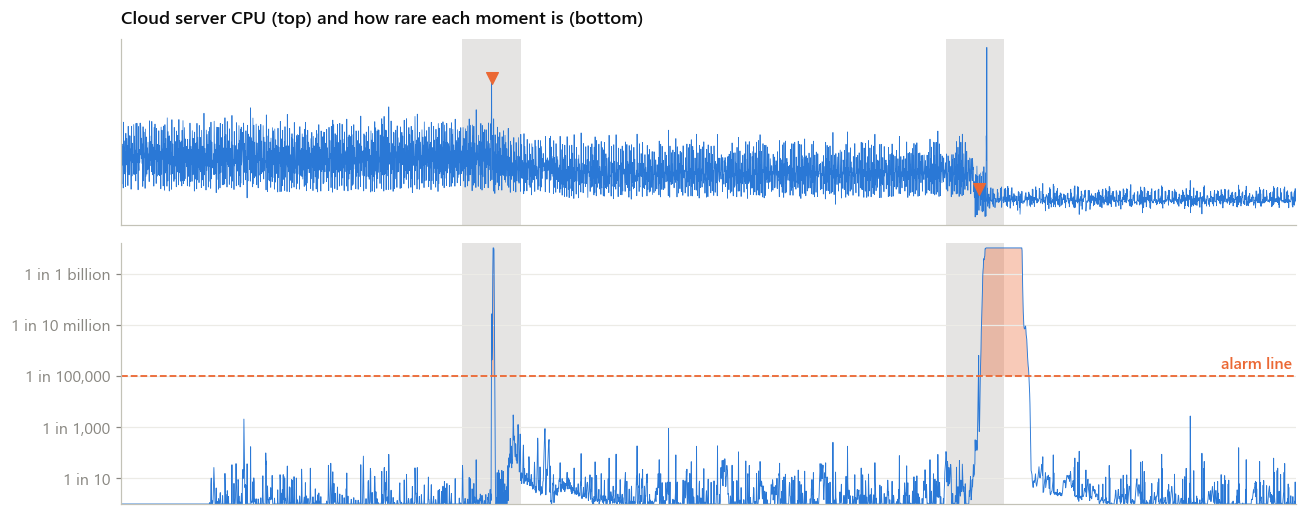

In [11]:
s = SERIES["realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"]
scores, labels, events = run_series(s.values, s.timestamps)       # first call also compiles the novelty search
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
bands(a1, s); a1.plot(s.values, color=BLUE, lw=0.5); alarms(a1, s, FINAL)
a1.set_title("Cloud server CPU (top) and how rare each moment is (bottom)"); a1.set_yticks([])
bands(a2, s)
a2.plot(np.minimum(scores, 10), color=BLUE, lw=0.6)
a2.fill_between(np.arange(len(s)), 5, np.minimum(scores, 10), where=scores >= 5, color=ORANGE, alpha=0.35, lw=0)
a2.axhline(5, color=ORANGE, ls="--", lw=1.2)
a2.set_yticks([1, 3, 5, 7, 9], [one_in(v) for v in (1, 3, 5, 7, 9)]); a2.set_ylim(0, 10.2)
a2.text(len(s), 5.3, "alarm line ", color=ORANGE, ha="right", fontweight="semibold")
a2.set_xlim(0, len(s)); a2.set_xticks([])
fig.tight_layout()
idx = [int(np.searchsorted(s.timestamps, np.datetime64(pd.Timestamp(e["timestamp"])))) for e in events]
real = sum(any(a <= i <= b for a, b in window_indices(s.timestamps, s.windows)) for i in idx)
print(f"{len(events)} alarms, {real} of them inside labelled anomalies")

<a id="5"></a>
## 5 · Watch it run on one signal

Tweets mentioning CVS: 15,853 values, one every 5 minutes, 3 labelled anomalies. This is the signal
from our live demo. We stream it through a fresh detector, point by point.

15,853 values in 0.63 s (40 µs per value) · 5 alarms · 3 of 3 anomalies caught · precision 80%


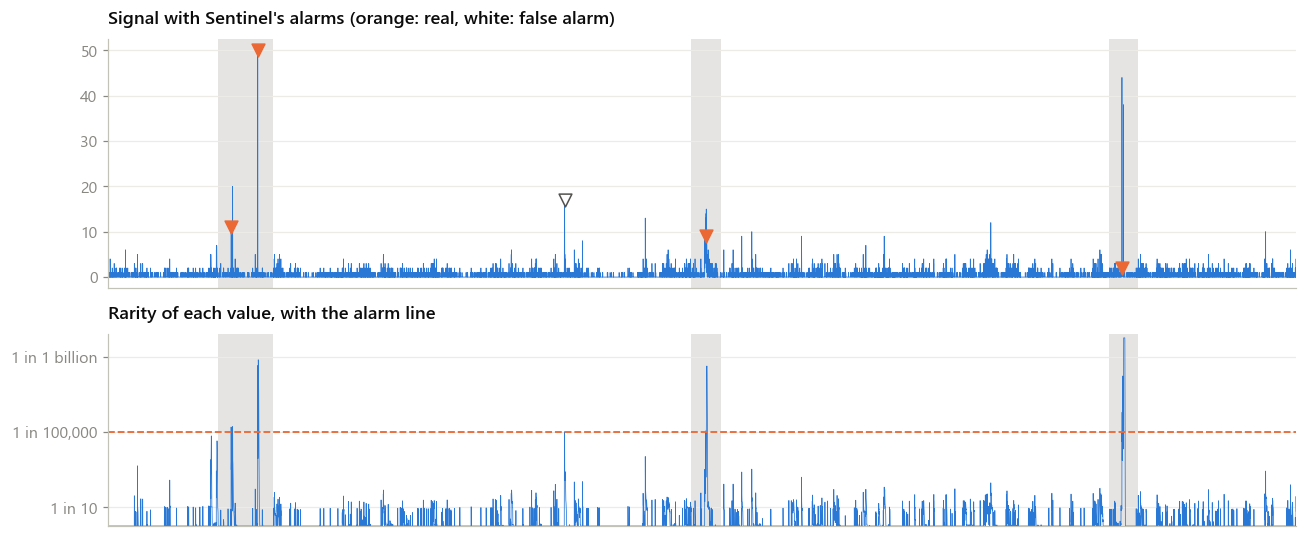

In [12]:
s = SERIES["realTweets/Twitter_volume_CVS.csv"]
t0 = time.perf_counter()
scores, labels, events = run_series(s.values, s.timestamps)
dt = time.perf_counter() - t0
res = evaluate_series(s.timestamps, labels, s.windows)
print(f"{len(s):,} values in {dt:.2f} s ({dt / len(s) * 1e6:.0f} µs per value) · {len(events)} alarms · "
      f"{res.n_detected} of {res.n_windows} anomalies caught · precision {res.precision:.0%}")

idx = [int(np.searchsorted(s.timestamps, np.datetime64(pd.Timestamp(e["timestamp"])))) for e in events]
inside = [any(a <= i <= b for a, b in window_indices(s.timestamps, s.windows)) for i in idx]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
bands(a1, s); a1.plot(s.values, color=BLUE, lw=0.5)
for i, ok in zip(idx, inside):
    a1.scatter(i, s.values[i], marker="v", s=70, zorder=5, color=ORANGE if ok else "white", edgecolors=ORANGE if ok else INK2)
a1.set_title("Signal with Sentinel's alarms (orange: real, white: false alarm)")
bands(a2, s); a2.plot(np.minimum(scores, 10), color=BLUE, lw=0.5); a2.axhline(5, color=ORANGE, ls="--", lw=1.2)
a2.set_yticks([1, 5, 9], [one_in(v) for v in (1, 5, 9)]); a2.set_ylim(0, 10.2)
a2.set_xlim(0, len(s)); a2.set_xticks([])
a2.set_title("Rarity of each value, with the alarm line")
fig.tight_layout()

Every alarm comes with **evidence**: which watcher fired, how rare the value was, and one sentence a
person can read. This is exactly what goes into `predictions/events.json`.

In [13]:
pd.DataFrame([{"time": e["timestamp"][:16].replace("T", " "), "watcher": EXPERT.get(e["expert"], e["expert"]), "score": e["score"],
               "rarity": one_in(e["score"]), "real anomaly?": "yes" if ok else "no (false alarm)",
               "explanation": e["explanation"]} for e, ok in zip(events, inside)])

,time,watcher,score,rarity,real anomaly?,explanation
0,2015-03-04 14:22,spike,5.26,"1 in 181,970",yes,Value 11.00 is 21.5 scales above the learned baseline 0.23 (normal band -1.27 to 1.73).
1,2015-03-05 19:57,spike,8.52,1 in 331 million,yes,Value 50.00 is 99.4 scales above the learned baseline 0.32 (normal band -1.18 to 1.82).
2,2015-03-20 01:12,spike,5.01,"1 in 102,329",no (false alarm),Value 17.00 is 33.5 scales above the learned baseline 0.26 (normal band -1.24 to 1.76).
3,2015-03-26 14:07,new level,5.05,"1 in 112,202",yes,Sustained level shift: recent mean 6.40 vs baseline 0.43 (8.2 scales above).
4,2015-04-14 21:02,new shape,6.05,1 in 1 million,yes,The last 8 points form a pattern not seen before: the closest past match (1750 steps ago) differs by 11.40 per point.


Text(0.0, 1.0, 'Inside one alarm (2015-03-05 19:57): the spike watcher fired')

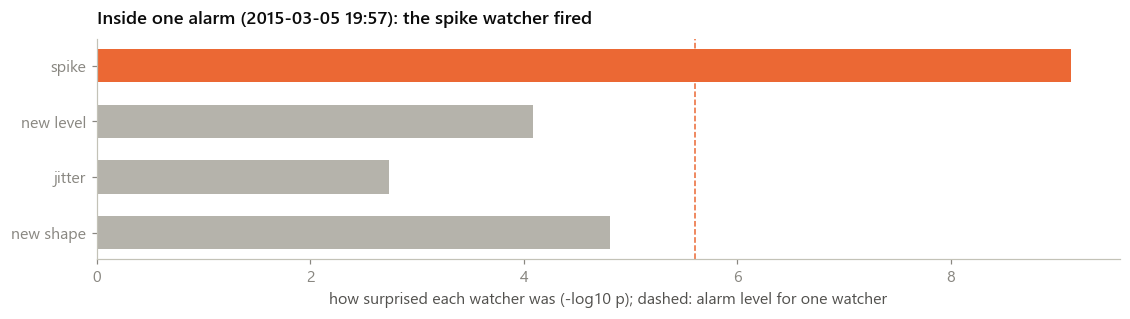

In [14]:
e = events[1]
names = list(e["experts"])
surprise = [-np.log10(max(e["experts"][n]["p"], 1e-300)) for n in names]
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.barh([EXPERT[n] for n in names][::-1], surprise[::-1],
        color=[ORANGE if n == e["expert"] else GREY for n in names][::-1], height=0.6)
ax.axvline(e["threshold"] + np.log10(len(names)), color=ORANGE, ls="--", lw=1)
ax.set_xlabel("how surprised each watcher was (-log10 p); dashed: alarm level for one watcher")
ax.grid(False)
ax.set_title(f"Inside one alarm ({e['timestamp'][:16].replace('T', ' ')}): the {EXPERT[e['expert']]} watcher fired")

<a id="6"></a>
## 6 · The two improvements of our final round

### 6.1 · Don't jump to conclusions (tail-shape shrinkage)
Right after warm-up a watcher has seen only about a dozen extreme values. The fitted tail shape
(γ) was often far too heavy, so the meter believed huge values were common and obvious spikes could
not alarm. We now shrink γ toward the light exponential tail until there is real evidence:
`γ ← γ · n / (n + 200)`. We replay one hourly ad-price signal up to a real spike, with and without it.

the spike is 111 noise units above normal
  before: tail shape γ = 0.44, an alarm needs 690  ->  missed
  now   : tail shape γ = 0.10, an alarm needs 79  ->  caught


Text(0.0, 1.0, 'The rarity meter for this signal, before and after shrinkage')

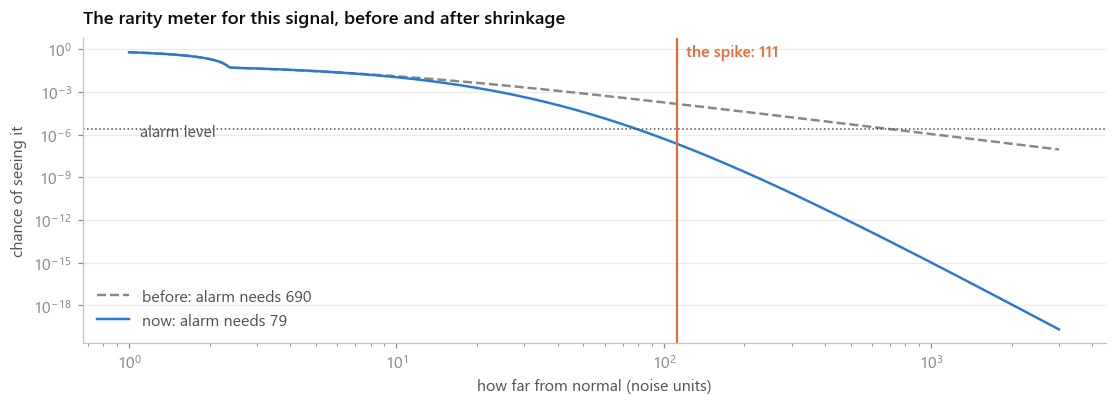

In [15]:
s = SERIES["realAdExchange/exchange-4_cpm_results.csv"]
i0 = 1276                                           # a labelled spike
fits = {}
for key, p in (("before", SentinelParams(tail_shrink=0, relearn=False)), ("now", SentinelParams())):
    sen = Sentinel(p, 3600.0)
    for i in range(i0):
        sen.update(s.timestamps[i], float(s.values[i]))
    j = [x.name for x in sen.experts].index("level")
    tail, spike = sen.tails[j], abs(sen.experts[j].score(float(s.values[i0])))
    p_alarm = p.risk / len(sen.experts)
    fits[key] = (tail, tail.level_for(p_alarm))
print(f"the spike is {spike:.0f} noise units above normal")
for key, (tail, need) in fits.items():
    print(f"  {key:6s}: tail shape γ = {tail.gamma:.2f}, an alarm needs {need:.0f}  ->  {'caught' if spike >= need else 'missed'}")

grid = np.geomspace(1, 3000, 400)
fig, ax = plt.subplots(figsize=(12, 3.6))
for key, col, ls in (("before", MUTED, "--"), ("now", BLUE, "-")):
    ax.loglog(grid, [fits[key][0].tail_prob(g) for g in grid], color=col, ls=ls, lw=1.6, label=f"{key}: alarm needs {fits[key][1]:.0f}")
ax.axvline(spike, color=ORANGE, lw=1.4); ax.text(spike * 1.08, 0.3, f"the spike: {spike:.0f}", color=ORANGE, fontweight="semibold")
ax.axhline(p_alarm, color=INK2, ls=":", lw=1); ax.text(1.1, p_alarm * 0.3, "alarm level", color=INK2)
ax.set_xlabel("how far from normal (noise units)"); ax.set_ylabel("chance of seeing it")
ax.legend(loc="lower left"); ax.set_title("The rarity meter for this signal, before and after shrinkage")

In [16]:
w = win[["series", "window", "type"]]
by_type = {}
for run in (1, 6):
    r = pd.read_csv(ROOT / "runs" / f"run_{run:02d}" / "windows.csv").merge(w, on=["series", "window"])
    by_type[f"run {run}"] = r.groupby("type").hit.sum()
caught = pd.DataFrame(by_type).astype(int)
caught.index = caught.index.map(NICE)
caught["of"] = win.type.map(NICE).value_counts()
caught

,run 1,run 6,of
type,,,
Level shift,10,11,14
Biggest spike ever seen,31,37,55
"Big spike, but seen before",11,11,32
Subtle change,6,6,15


### 6.2 · Accept a new normal (re-learning)
If the alarm condition is still on when the 300-value quiet period ends, the signal has changed for
good. Sentinel then rebuilds its watchers from the last 300 values instead of alarming again and again.
Saved alarms of run 2 (before) and run 6 (final) on a disk-write signal:

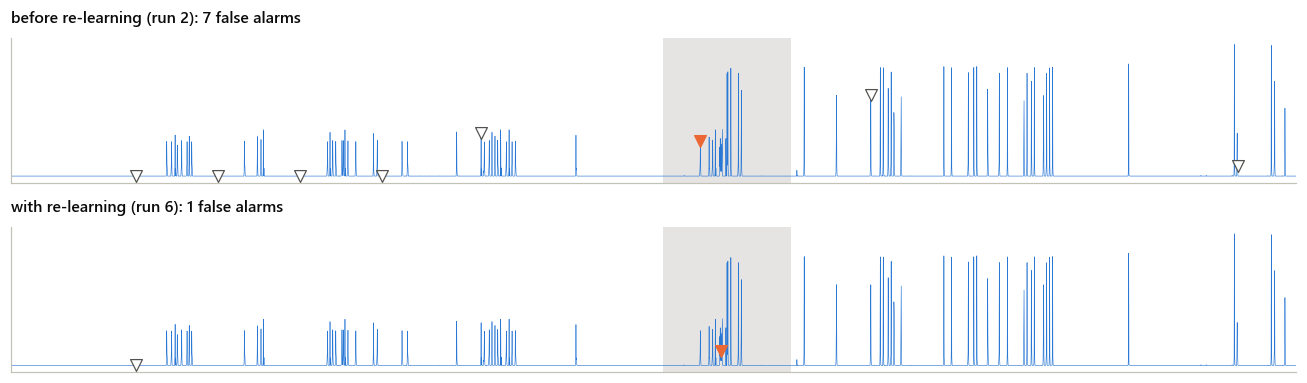

In [17]:
s = SERIES["realAWSCloudwatch/ec2_disk_write_bytes_1ef3de.csv"]
fig, axes = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True)
for ax, run, lab in zip(axes, (2, 6), ("before re-learning (run 2)", "with re-learning (run 6)")):
    a = pd.read_csv(ROOT / "runs" / f"run_{run:02d}" / "alarms.csv")
    bands(ax, s); ax.plot(s.values, color=BLUE, lw=0.4)
    got = alarms(ax, s, a)
    ax.set_title(f"{lab}: {int((~got.hit).sum())} false alarms", fontsize=10.5)
    ax.set_yticks([]); ax.set_xlim(0, len(s)); ax.set_xticks([])
fig.tight_layout()

<a id="7"></a>
## 7 · Experiments under a 15-run budget

One run = the detector on all 58 signals, scored once. Each run had a written hypothesis before it
started, and a change was kept only if event-F1 rose **and** more categories gained than lost. Ideas
were first tested on saved outputs, for free. 7 runs used, 8 kept in reserve.

In [18]:
log = pd.read_csv(ROOT / "runs" / "run_log.csv")
log[["run", "changes", "f1", "precision", "recall", "detected", "alarms", "fp", "decision"]].rename(
    columns={"changes": "change", "f1": "event-F1", "detected": "windows found", "fp": "false alarms"})

,run,change,event-F1,precision,recall,windows found,alarms,false alarms,decision
0,1,(none),0.5514,0.6146,0.5000,58,96,37,reference
1,2,tail_shrink=100,0.5611,0.5804,0.5431,63,112,47,keep
2,3,tail_shrink=400,0.5437,0.5360,0.5517,64,125,58,drop
3,4,tail_shrink=100 relearn=true,0.5838,0.6311,0.5431,63,103,38,keep
4,5,tail_shrink=100 relearn=true warmup=200,0.5555,0.5593,0.5517,64,118,52,drop
5,6,tail_shrink=200 relearn=true,0.5941,0.6321,0.5603,65,106,39,keep
6,7,tail_shrink=400 relearn=true,0.5706,0.5909,0.5517,64,110,45,drop


Text(0.0, 1.0, 'From 0.343 to 0.594')

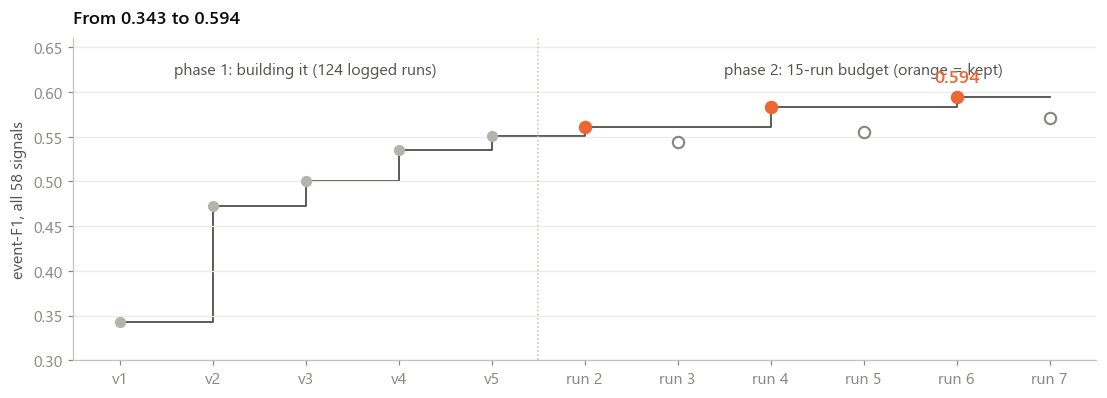

In [19]:
phase1 = [("v1", 0.343), ("v2", 0.473), ("v3", 0.500), ("v4", 0.535), ("v5", 0.551)]   # README, experiment history
phase2 = [(f"run {r.run}", r.f1, r.decision) for r in log.itertuples() if r.run > 1]
names = [n for n, _ in phase1] + [n for n, _, _ in phase2]
vals = [v for _, v in phase1] + [v for _, v, _ in phase2]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.step(range(len(vals)), np.maximum.accumulate(vals), where="post", color=INK2, lw=1.2, zorder=1)
ax.scatter(range(5), [v for _, v in phase1], color=GREY, s=40, zorder=2)
for k, (_, v, d) in enumerate(phase2, start=5):
    ax.scatter(k, v, s=55, zorder=3, color=ORANGE if d == "keep" else "white", edgecolors=ORANGE if d == "keep" else MUTED, linewidths=1.4)
ax.axvline(4.5, color=LINE, ls=":")
ax.text(2, 0.62, "phase 1: building it (124 logged runs)", ha="center", color=INK2)
ax.text(8, 0.62, "phase 2: 15-run budget (orange = kept)", ha="center", color=INK2)
ax.annotate(f"{max(vals):.3f}", (names.index("run 6"), max(vals)), xytext=(0, 10), textcoords="offset points",
            ha="center", color=ORANGE, fontweight="semibold", fontsize=12)
ax.set_xticks(range(len(names)), names); ax.set_ylim(0.3, 0.66); ax.set_ylabel("event-F1, all 58 signals")
ax.set_title("From 0.343 to 0.594")

<a id="8"></a>
## 8 · Evaluation and results

**How it is scored (event-level):** a run of consecutive ANOMALOUS values is one alarm. A labelled
window counts as caught if any alarm touches it. **Precision** = alarms that hit a window / all
alarms. **Recall** = windows caught / all windows. **Delay** = first alarm minus the labelled anomaly
point. One configuration for all 58 signals; hiding a whole category and tuning on the rest still gives
0.594; the 5 anomaly-free signals get 0 alarms.

In [20]:
m = json.loads((ROOT / "predictions" / "metrics.json").read_text())
per = pd.DataFrame(m["per_category"]).T
per = per[per.windows > 0][["windows", "detected", "alarms", "fp", "precision", "recall", "f1"]]
per.index = per.index.map(CAT)
per = per.sort_values("f1", ascending=False)
per.loc["All 58 signals"] = [m["overall"][k] for k in ("windows", "detected", "alarms", "fp", "precision", "recall", "f1")]
per.rename(columns={"detected": "caught", "fp": "false alarms", "f1": "event-F1"})

,windows,caught,alarms,false alarms,precision,recall,event-F1
"Synthetic, with anomalies",6.0,5.0,5.0,0.0,1.0000,0.8333,0.9091
Twitter mentions,33.0,25.0,47.0,20.0,0.5745,0.7576,0.6534
Known failures,19.0,12.0,23.0,11.0,0.5217,0.6316,0.5714
Cloud servers (AWS),30.0,14.0,21.0,7.0,0.6667,0.4667,0.5490
Online ad prices,14.0,5.0,5.0,0.0,1.0000,0.3571,0.5263
Road traffic,14.0,4.0,5.0,1.0,0.8000,0.2857,0.4211
All 58 signals,116.0,65.0,106.0,39.0,0.6321,0.5603,0.5941


,method,event-F1,precision,recall,false alarms,µs per value
0,Sentinel (ours),0.5941,0.6321,0.5603,39,60.60
1,Local Outlier Factor,0.2609,0.1651,0.6207,455,215.69
2,Isolation Forest,0.2491,0.1767,0.4224,261,49.46
3,One-Class SVM,0.2345,0.1416,0.6810,594,8.69
4,Rolling z-score,0.2257,0.1481,0.4741,351,0.50


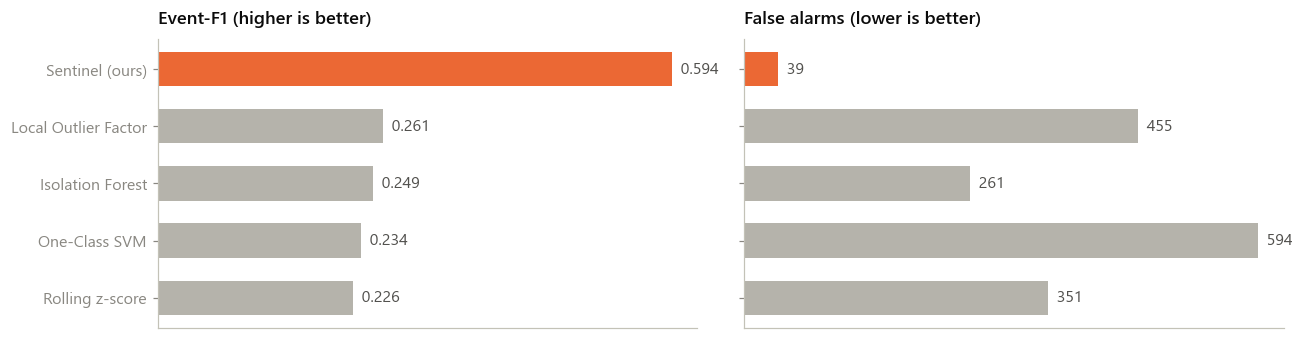

In [21]:
base = pd.read_csv(ROOT / "results" / "baselines.csv")
NAMES = {"lof": "Local Outlier Factor", "isolation_forest": "Isolation Forest", "ocsvm": "One-Class SVM", "rolling_z": "Rolling z-score"}
rt = json.loads((ROOT / "predictions" / "runtime.json").read_text())
cmp = pd.DataFrame([{"method": "Sentinel (ours)", "event-F1": m["overall"]["f1"], "precision": m["overall"]["precision"],
                     "recall": m["overall"]["recall"], "false alarms": m["overall"]["fp"], "µs per value": rt["latency_us_p50"]}]
                   + [{"method": NAMES[r.method], "event-F1": r.f1, "precision": r.precision, "recall": r.recall,
                       "false alarms": r.fp, "µs per value": r.us_per_point} for r in base.itertuples()])
cmp = cmp.sort_values("event-F1", ascending=False).reset_index(drop=True)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
colors = [ORANGE if n.startswith("Sentinel") else GREY for n in cmp.method]
a1.barh(cmp.method[::-1], cmp["event-F1"][::-1], color=colors[::-1], height=0.6)
a2.barh(cmp.method[::-1], cmp["false alarms"][::-1], color=colors[::-1], height=0.6)
for ax, col, fmt in ((a1, "event-F1", "{:.3f}"), (a2, "false alarms", "{:.0f}")):
    for y, v in enumerate(cmp[col][::-1]):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK2)
    ax.grid(False); ax.set_xticks([])
a1.set_title("Event-F1 (higher is better)"); a2.set_title("False alarms (lower is better)")
fig.tight_layout()
cmp

> Each standard method was given its **best possible threshold, picked using the answers**. Sentinel
> uses one fixed setting and still scores **2.3×** the best of them, with 7 to 15 times fewer false alarms.

speed: 60.6 µs per value (p50), 121.1 µs (p99), 16,040 values per second per core


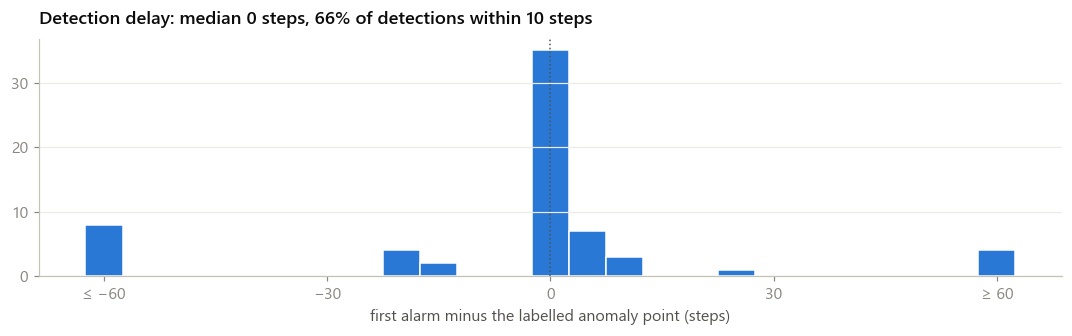

In [22]:
delay = pd.read_csv(ROOT / "results" / "detection_delay.csv").pts
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.hist(delay.clip(-60, 60), bins=np.arange(-62.5, 63, 5), color=BLUE, edgecolor="white")
ax.axvline(0, color=INK2, ls=":")
ax.set_xticks([-60, -30, 0, 30, 60], ["≤ −60", "−30", "0", "30", "≥ 60"])
ax.set_xlabel("first alarm minus the labelled anomaly point (steps)")
ax.set_title(f"Detection delay: median {m['median_delay_from_label_pts']:.0f} steps, "
             f"{m['pct_detections_within_10_pts_of_label']:.0f}% of detections within 10 steps")
print(f"speed: {rt['latency_us_p50']} µs per value (p50), {rt['latency_us_p99']} µs (p99), "
      f"{rt['throughput_points_per_sec_per_core']:,} values per second per core")

### Why we do not use point adjustment
Many papers count a whole window as found once any point in it fires. On NAB that lets **random
alarms** beat a real detector, so we report the challenge's event-F1 only (`scripts/metric_check.py`):

In [23]:
pd.read_csv(ROOT / "results" / "metric_check.csv").rename(columns={
    "detector": "detector", "event_f1": "event-F1 (challenge metric)", "pointwise_f1": "point-wise F1",
    "point_adjusted_f1": "point-adjusted F1", "events": "alarms"})

,detector,event-F1 (challenge metric),point-wise F1,point-adjusted F1,alarms
0,Sentinel (run 6),0.594,0.045,0.823,106
1,"random, 0.28% of points (our alarm rate)",0.146,0.005,0.765,1032
2,"random, 1% of points",0.163,0.018,0.919,3600
3,flag every point,0.945,0.168,0.168,58


<a id="9"></a>
## 9 · Limits and next steps

**Where it still fails**
* **"Seen before" spikes:** when an equally big spike came earlier without a label, rarity alone cannot
  tell them apart (11 of 32 caught).
* **Short hourly signals:** little history to learn from (online ads: 5 of 14).
* **Warm-up:** the first 300 values are for learning only; 3 anomalies start there.
* **Unlabelled bursts:** most of the 39 false alarms are big Twitter bursts that nobody labelled.

**Next**
* Learn from feedback: an operator's "not a problem" goes into the tail, so the pattern stops alarming.
* Weekly and holiday rhythm for demand signals.
* Watch related signals together (CPU, disk and network of one machine).

**Reproduce**
```bash
pip install -r requirements.txt
python predict.py                 # all 58 signals -> predictions/ (predictions.csv, events.json, metrics.json)
python scripts/eda.py             # EDA tables and figures
streamlit run app.py              # Python demo
python -m http.server 8080 --directory web   # presentation at /, live web demo at /demo/
```

---
*Sentinel catches 65 of 116 real problems, live, at about 16,000 values a second, and explains every alarm.*